# Case Study 25 — Predicting Return-to-Origin (RTO) on Cash-on-Delivery Orders at Checkout

**Priority:** ★★★ Must-visit · **Reference:** Case Study 25 — *Flipkart (with IIIT Delhi / IIIT Hyderabad): Social re-identification assisted RTO detection* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Checkout and Payments, Logistics, Trust and Safety, Finance, Legal / Privacy
**Data:** ⚠️ **SYNTHETIC** (D-25-01). Order data and the professional-network profiles used in the paper are confidential/private; this is a calibrated simulation with hidden ground truth.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs25_cod_rto_prediction.ipynb`

## 0. Executive Summary for Business

*(Synthetic COD orders with a hidden risk model, built on the documented design of the Flipkart / IIIT Delhi / IIIT Hyderabad study of social re-identification for RTO detection. The company's orders and the profile data are confidential; none of it is reproduced, and our recall is lower than the paper's reported range. Written after the analysis.)*

- **The question:** can we predict at checkout which cash-on-delivery orders will come back (RTO), without wrongly flagging good customers, does public social-profile data help, and what is it worth in rupees?
- **A history-only model already works.** On the last month (6,745 orders, 32.2% RTO) gradient boosting on order-history features reaches **AUC 0.7925** (CI 0.7814 to 0.8029). With flagging capped at about 3% of good orders it catches **23.7%** of RTO orders. Logistic regression is lower (AUC 0.758), and Random Forest is close to gradient boosting.
- **Social data adds a small, real gain.** The full model has **AUC 0.8066** (CI 0.7976 to 0.8181), **recall 25.9%** (CI 24.3% to 27.9%) and **precision 81.6%** at a 3% false-positive rate (realised 2.78%). Over history alone this is **+0.0141 AUC** and +2.2 points of recall on all orders (McNemar, Holm p = 0.0013). Among re-identified users it is **+0.0325 AUC and +5.7 points of recall**, and for thin-history users +0.0208 AUC and +4.4 points. The embedding adds little beyond the quantitative profile features (+0.0014 AUC).
- **The randomised holdout matters for honesty, less for ranking.** A model trained on the legacy-logged data (blocked orders unobserved) sees an RTO rate of **27.1% against 31.7%**, and the blocked orders would have been RTO **56.2%** of the time. Its AUC is almost the same (0.787 vs 0.793), but its false-positive rate overshoots the 3% cap (**4.65% vs 2.78%**), and it flags more only because of that.
- **Matching strictness:** at match score 0.6, **98.1%** of matches are the right person and 86% of found profiles are kept; at 0.4 precision falls to 94.3%. Model AUC barely changes across thresholds (0.792 to 0.807).
- **Calibration is imperfect.** Overall predicted/observed is 1.005, but the slope is 1.106 and Hosmer-Lemeshow rejects (p = 0.0035). Fairness is not clean either: false-positive rates range from **1.4% (senior managers) to 4.2% (other / not stated)**, omnibus p = 0.042, no pairwise gap survives Holm correction.
- **Money (assumed ₹180 per RTO, nudge success 50%, 25% loss of flagged good orders, 1 lakh COD orders a day):** the capped rule saves about **₹24.7 crore a year** (CI 22.6 to 27.0; worst 12.2, best 37.3). A pure cost rule would show ₹64.6 crore but flags **62.8% of orders** and 52% of good ones, so we do not recommend it.
- **A/B test:** a nudge that cuts RTO among flagged orders by 35% needs about **764 COD orders in total**, and one that cuts it by 20% needs 2,193, with the loss on good orders measured as a second outcome.
- **I recommend:** use the capped threshold (3% false-positive rate) with history features, add the social features only for strictly matched users after legal review, keep a 5% randomised holdout, and prove the saving in an A/B test.

## 1. The Problem in Simple English

On cash-on-delivery (COD) an order can fail in a costly way: the parcel is shipped, the customer refuses or cannot be reached, and it travels **back to the seller** — a **Return-to-Origin (RTO)**. The platform pays for **two-way shipping and handling**, and the item was unavailable to other buyers in the meantime. In India, COD is a very large share of orders (the Meesho prospectus reports 72% of orders in the six months to September 2025), so RTO is a major cost.

At checkout the platform can still act: ask for prepayment, send a confirmation call or OTP, or block COD. To do this it must **predict, before shipping, which orders will become RTO**, without annoying the many good COD customers. Three questions follow:

1. How well can **order history alone** (RTO rates of the user, the pin code, the seller …) predict RTO?
2. Does adding **public social-profile information** (found by matching a name and city) help, and for whom?
3. Is it **safe and fair** to use such data, and how much money would it save?

Leaders and interviewers want to know:
1. How good is the model at a **false-positive cap** that protects customer experience?
2. Why the **5% randomised, un-intervened holdout** is the key design idea.
3. How the **threshold** should be chosen: a cap, or the money?
4. What the **A/B test** has to look like.
5. What **privacy and fairness** risks come with social-profile features.

## 2. Reference from the Case File

### (a) What the Flipkart team did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Predict at checkout whether a **COD** order becomes RTO (cancelled while in transit). Losses: logistics cost (to the point of cancellation, back and restocking) and opportunity cost. The authors say RTO "by uninformed customers or bad actors" can cause losses of "double-digit million dollars annually" (company-team claim, no breakdown) |
| Data | Past orders and outcomes; a **5% randomised control set** with no intervention (to avoid bias from other checkout models; only COD orders used); past-trend features (RTO ratio over 3 months and 1 year for user, product, seller, category, pin code, street, city; hour and weekday); social profile (student flag, number of jobs and degrees, friends and followers, years working and in education; S-BERT embeddings of job and education text); November 2021 to April 2022 with the **first 5 months for training and the last month for testing**; final dataset **6,881 orders from 2,121 users, 32% RTO** |
| Re-identification | Name + city searched on a professional network and a web search engine; candidate found for **1,091 of 2,121** users; names must match and a **match score** (share of the profile's locations also in the user's order cities, fuzzy-matched) must exceed a threshold (reported at 0.6). At 0.6: exact match **68.92%**, multiple **17.68%**, no match **13.40%**; at 1.0 no match rises to **40.02%** |
| Models | Random Forest, XGBoost, TabNet; **Random Forest best**; tabular deep net worse |
| Results (company-team, test month) | Random Forest, precision / recall / "Goodness" (bps): past trends **85.7 / 40.3 / 1,005.7**; + social quantitative **85.7 / 50.4 / 1,305.6**; + abstractive embeddings **88.8 / 60.2 / 1,633.7**. XGBoost all features 86.8 / 44.5 / 1,129.4; TabNet all features 64.2 / 15.1 / 320.0. The threshold maximises Goodness subject to a **false-positive-rate cap** (value ND) |
| Not documented | Significance tests and confidence intervals, deployment, A/B results, rupee savings, the intervention used (prepay, block, verify), the Goodness formula (equation 2 was not read), the cap value |
| Caveats stated | India-only data; social re-identification covered only a subset (1,091 of 2,121 users); privacy |

**Source:** Hitkul, Abinaya K, Soham Saha, Satyajit Banerjee, Muthusamy Chelliah, Ponnurangam Kumaraguru, "Social Re-Identification Assisted RTO Detection for E-Commerce", WWW '23 Companion, DOI 10.1145/3543873.3587620 (peer-reviewed workshop paper). Meesho COD share: MediaNama report on the RHP (Dec 2025); not an RTO model.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 40,000 COD orders in a randomised control set over 180 days from 14,000 users, 600 pin codes, 300 sellers and 20 categories, plus a second **legacy-logged** dataset where an old rule blocks risky orders (outcome never observed). Hidden truth: each user's reliability, occupation type and effects of pin code, seller and category |
| Calibration to the documented | **32%** RTO share; **51%** of users with a candidate profile; about **85%** of found profiles matched at 0.6; **5 months train, 1 month test** |
| Not calibrated | The paper's high recall (40% to 60%) is much higher than ours; we did not force that. Our signal strengths are assumptions |
| Methods compared | Logistic regression, Random Forest, gradient boosting (instead of XGBoost, which is outside the allowed libraries); no TabNet (the paper found it worse) |
| Statistics added | Time-ordered split; **selection bias** from training on intervened logs; re-identification threshold sensitivity (match precision with hidden truth); **paired tests** for each feature group (bootstrap and McNemar with Holm); operating point at a **3% false-positive cap** (threshold from out-of-fold scores); calibration (slope, Hosmer–Lemeshow); fairness diagnostics by hidden occupation group; cost-based thresholds; **A/B power** |
| Goodness | Our own definition: reduction in the RTO ratio (in basis points) among unflagged orders versus all orders, because the paper's formula was not read. It is **not** the paper's number |

### (c) How the industry uses this

COD risk scoring (block or prepay-nudge for risky pin codes, new buyers, high-value orders) is standard in Indian marketplaces and D2C brands; sellers see RTO as a major cost and platforms use history plus address quality. Public detail is scarce. This is an **interview-standard** treatment of an **imbalanced, cost-sensitive classification** problem with a **selection-bias** trap.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which COD orders should we nudge to prepay or verify, without losing many good orders? |
| Analytical | At a fixed false-positive cap, how much recall do order-history features give, how much do social-profile features add (overall and for the re-identified subset), and what is the net ₹ effect? |

**Hypotheses**
- **H1 (label design):** H0: a model trained on labels from an intervened (legacy-blocked) flow performs the same on random-control orders as one trained on the randomised control set.
- **H2 (re-identification):** H0: the match precision at 0.6 is no higher than at lower thresholds; coverage falls as the threshold rises.
- **H3 (feature value):** H0: adding social quantitative (and then embedding) features does not change AUC, recall at the cap or Goodness (paired bootstrap; McNemar; Holm).
- **H4 (calibration):** H0: the predicted risk is calibrated (slope 1, Hosmer–Lemeshow).
- **H5 (fairness):** H0: the false-positive rate is equal across occupation groups (chi-square).
- **H6 (value):** H0: the cost-optimal and capped thresholds give the same net saving per 1,000 orders.

**Primary metrics:** recall and precision at the **3% false-positive-rate cap** on the last month; **Goodness** (our definition). **Secondary:** AUC, PR-AUC, calibration, net ₹ saving.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public COD / RTO order data for India | **None.** Public sets with delivery outcomes (Olist, Kaggle ecommerce) are Brazilian or US, have no COD flag, no RTO label and no social profile. |
| The paper's data | Private (and the profile data raises privacy limits). |
| **Decision** | Synthetic orders with hidden user reliability and occupation types and a re-identification process, calibrated to the documented 32% RTO share and coverage, so that selection bias, threshold sensitivity and fairness can be checked against the truth (D-25-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs25.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 25 (COD return-to-origin prediction, Flipkart / IIIT research)
===================================================================================================
THIS DATA IS SYNTHETIC. Flipkart's order data and the profile data used in the paper are confidential/private.

Documented context (Hitkul et al., "Social Re-Identification Assisted RTO Detection for E-Commerce", WWW '23 Companion):
COD orders only; a 5% randomised, un-intervened control set gives clean labels; past-trend features (RTO ratio for user,
product, seller, category, pin code over 3 months and 1 year); social-profile features obtained by re-identifying the user
on a public professional network (name + city, candidate found for 1,091 of 2,121 users, exact match 68.9% / multiple 17.7% /
no match 13.4% at threshold 0.6); 32% of the final orders were RTO; Nov 2021 - Apr 2022 with the first 5 months as train and
the last month as test.

Simulation (our assumptions; only the 32% RTO rate, 51% candidate coverage and ~87% matched-at-0.6 are calibrated to the paper):
  * 14,000 users, 600 pin codes, 300 sellers, 20 categories, 40,000 COD orders in the randomised control set (days 0-179).
  * RTO propensity = user effect + pin-code effect (drifting by month) + seller + category + order features.
    The user effect is partly driven by a hidden socio-economic "reliability" r_u and a hidden occupation type (6 types).
  * Past-trend features are noisy: counts drawn from the entities' true rates (users have few past orders, so their trend is thin).
  * Social features exist only for users with a found profile, and a wrong candidate is matched sometimes (its profile is someone else's).
  * A second dataset ("legacy_logged") has the same distribution but an old rule blocks risky COD orders, so their outcome is never observed.
Hidden truth columns are prefixed "_".

Outputs: data/cs25/control_orders.csv.gz, data/cs25/legacy_logged_orders.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.optimize import brentq

SEED = 42
N_USERS, N_PIN, N_SELLER, N_CAT, N_ORD, DAYS = 14_000, 600, 300, 20, 40_000, 180
N_TYPES, EMB = 6, 8
TYPE_NAMES = ["student", "early career", "mid-career professional", "self-employed / business", "senior manager", "other / not stated"]
TYPE_EFF = np.array([0.50, 0.30, -0.30, 0.20, -0.50, 0.60])
TARGET_RTO = 0.32


def _sig(z):
    return 1 / (1 + np.exp(-z))


def _world(rng):
    """Users, entities and their hidden effects."""
    typ = rng.choice(N_TYPES, N_USERS, p=[0.14, 0.26, 0.22, 0.16, 0.08, 0.14])
    r = rng.normal(0, 1, N_USERS)                                           # hidden reliability
    user_eff = -1.30 * r + 1.10 * TYPE_EFF[typ] + rng.normal(0, 0.40, N_USERS)
    users = pd.DataFrame({"user_id": np.arange(N_USERS), "_type": typ, "_reliability": r, "_user_effect": user_eff})
    # profile (what a re-identified public profile would show)
    users["is_student"] = (typ == 0).astype(int)
    users["n_jobs"] = rng.poisson(np.array([0.3, 1.2, 2.5, 2.0, 3.5, 1.0])[typ])
    users["n_degrees"] = 1 + rng.poisson(np.array([0.3, 0.5, 0.7, 0.4, 0.8, 0.3])[typ])
    users["friends"] = np.round(np.exp(rng.normal(5.0 + 0.5 * r, 0.7) + 0.2 * (typ == 4))).astype(int)
    users["followers"] = np.round(np.exp(rng.normal(4.6 + 0.6 * r, 0.8) + 0.2 * (typ >= 3))).astype(int)
    users["years_working"] = np.round(np.clip(rng.normal(np.array([0.3, 3, 9, 8, 16, 4])[typ], 2.5), 0, 40), 1)
    users["years_education"] = np.round(np.clip(rng.normal(np.array([13, 16, 17, 15, 17, 14])[typ] + 0.8 * r, 1.2), 8, 24), 1)
    cent = np.random.default_rng(7).normal(0, 1, (N_TYPES, EMB))            # embedding centroid per occupation type
    emb = cent[typ] + rng.normal(0, 1.1, (N_USERS, EMB))
    for k in range(EMB): users[f"emb_{k}"] = np.round(emb[:, k], 3)
    ent = dict(pin_eff=rng.normal(0, 1.0, N_PIN), pin_drift=rng.normal(0, 0.18, (N_PIN, 7)).cumsum(1), seller_eff=rng.normal(0, 0.70, N_SELLER), cat_eff=rng.normal(0, 0.45, N_CAT))
    # re-identification outcome per user
    found = rng.random(N_USERS) < 0.51
    correct = rng.random(N_USERS) < 0.88
    score = np.where(correct, rng.beta(9, 2, N_USERS), rng.beta(2.5, 4, N_USERS))
    users["found_profile"] = found.astype(int); users["match_score"] = np.where(found, np.round(score, 3), np.nan); users["_true_match"] = np.where(found, correct.astype(int), -1)
    wrong_src = rng.integers(0, N_USERS, N_USERS)                           # a wrong candidate shows someone else's profile
    prof_cols = ["is_student", "n_jobs", "n_degrees", "friends", "followers", "years_working", "years_education"] + [f"emb_{k}" for k in range(EMB)]
    shown = users[prof_cols].copy(); wrong = found & ~correct; shown.loc[wrong] = users.loc[wrong_src[wrong], prof_cols].values
    users[prof_cols] = shown
    users["user_activity"] = rng.lognormal(np.log(1.6), 0.8, N_USERS)       # expected orders per year before the study (thin for many)
    users["_order_weight"] = rng.lognormal(0, 0.9, N_USERS)
    return users, ent, prof_cols


def _orders(rng, users, ent, n, c0, scale_c):
    uid = rng.choice(N_USERS, n, p=users["_order_weight"] / users["_order_weight"].sum())
    day = np.sort(rng.integers(0, DAYS, n)); month = np.minimum(day // 30, 5)
    pin = rng.integers(0, N_PIN, n); seller = rng.integers(0, N_SELLER, n); cat = rng.integers(0, N_CAT, n)
    hour = np.clip(np.round(rng.normal(15, 5.5, n)), 0, 23).astype(int); weekday = (day + 1) % 7
    value = np.round(np.exp(rng.normal(np.log(700), 0.8, n)), 0)
    night = ((hour >= 23) | (hour <= 4)).astype(int)
    o = pd.DataFrame({"user_id": uid, "day": day, "hour": hour, "weekday": weekday, "category": cat, "seller_id": seller, "pincode_id": pin, "order_value_inr": value})
    pin_now = ent["pin_eff"][pin] + ent["pin_drift"][pin, month + 1]
    logit = c0 + users["_user_effect"].values[uid] + pin_now + ent["seller_eff"][seller] + ent["cat_eff"][cat] + 0.40 * (np.log(value) - np.log(700)) + 0.25 * night + 0.12 * (weekday >= 5)
    o["_p_rto"] = _sig(logit)
    # past-trend features: noisy counts from the entities' own rates (information available at checkout)
    def trend(rate_3m, rate_1y, n3, n1):
        k3 = rng.binomial(n3, rate_3m); k1 = rng.binomial(n1, rate_1y)
        return np.where(n3 > 0, k3 / np.maximum(n3, 1), np.nan), n3, np.where(n1 > 0, k1 / np.maximum(n1, 1), np.nan), n1
    ur = _sig(c0 * scale_c + users["_user_effect"].values[uid]); n1 = rng.poisson(users["user_activity"].values[uid] * 1.2); n3 = rng.binomial(n1, 0.3)
    o["user_rto_3m"], o["user_n_3m"], o["user_rto_1y"], o["user_n_1y"] = trend(ur, ur, n3, n1)
    for name, eff_now, eff_old, nn in (("pin", pin_now, ent["pin_eff"][pin] + ent["pin_drift"][pin, np.maximum(month - 1, 0)], 90), ("seller", ent["seller_eff"][seller], ent["seller_eff"][seller], 160), ("cat", ent["cat_eff"][cat], ent["cat_eff"][cat], 900)):
        n1y = rng.poisson(nn * 4, n); n3m = rng.binomial(n1y, 0.28)
        r3 = _sig(c0 * scale_c + 0.9 * eff_old); r1 = _sig(c0 * scale_c + 0.9 * eff_old * 0.8)
        o[f"{name}_rto_3m"], _, o[f"{name}_rto_1y"], _ = trend(r3, r1, n3m, n1y)
    o["pin_rto_3m"] = o["pin_rto_3m"].round(3)
    for col in [c for c in o.columns if c.endswith(("_3m", "_1y")) and "_n_" not in c]: o[col] = o[col].round(3)
    soc = users.drop(columns=[c for c in users.columns if c in ("_order_weight", "user_activity")])
    o = o.merge(soc, on="user_id", how="left")
    o.insert(0, "order_id", np.arange(n)); o["rto"] = (rng.random(n) < o["_p_rto"]).astype(int)
    return o


def generate(seed=SEED):
    rng = np.random.default_rng(seed); users, ent, prof_cols = _world(rng)
    # intercept calibrated to the documented 32% RTO share
    probe = _orders(np.random.default_rng(seed + 1), users, ent, 12_000, 0.0, 0.0)
    c0 = brentq(lambda c: _sig(np.log(probe["_p_rto"] / (1 - probe["_p_rto"])) + c).mean() - TARGET_RTO, -4, 4)
    control = _orders(rng, users, ent, N_ORD, c0, 1.0)
    legacy = _orders(rng, users, ent, N_ORD, c0, 1.0)
    blocked = ((legacy.user_n_3m >= 1) & (legacy.user_rto_3m >= 0.9)) | (legacy.pin_rto_3m >= 0.46) | ((legacy.user_n_1y >= 3) & (legacy.user_rto_1y >= 0.6))
    legacy["legacy_blocked"] = blocked.astype(int); legacy["_rto_if_shipped"] = legacy["rto"]; legacy.loc[blocked, "rto"] = np.nan
    control["legacy_blocked"] = 0
    # data-quality defects (control only)
    dup = control.sample(n=600, random_state=seed); control = pd.concat([control, dup], ignore_index=True)
    control.loc[rng.random(len(control)) < 0.01, "order_value_inr"] = np.nan
    bad = rng.random(len(control)) < 0.002; control.loc[bad, "order_value_inr"] = 9_999_999
    bad = rng.random(len(control)) < 0.003; control.loc[bad, "hour"] = 25
    return control, legacy, dict(prof_cols=prof_cols, c0=c0, type_names=TYPE_NAMES)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); out = os.path.join(here, "cs25"); os.makedirs(out, exist_ok=True)
    ctl, leg, tp = generate()
    ctl.to_csv(os.path.join(out, "control_orders.csv.gz"), index=False); leg.to_csv(os.path.join(out, "legacy_logged_orders.csv.gz"), index=False)
    print("control rows", len(ctl), "RTO rate", ctl.rto.mean().round(4), "| legacy blocked share", leg.legacy_blocked.mean().round(3), "| observed-label RTO rate (legacy)", leg.rto.mean().round(4))
    print("found profile share (orders)", ctl.found_profile.mean().round(3), "| thin history (n_1y<=1) share", (ctl.user_n_1y <= 1).mean().round(3))

Overwriting data/generate_cs25.py


In [3]:
os.makedirs("data/cs25", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs25 as gen; importlib.reload(gen)
t0 = time.time(); ctl, leg, TP = gen.generate(seed=SEED); GZ = {"method": "gzip", "compresslevel": 1}
ctl.to_csv("data/cs25/control_orders.csv.gz", index=False, compression=GZ); leg.to_csv("data/cs25/legacy_logged_orders.csv.gz", index=False, compression=GZ)
print(f"control set {len(ctl):,} rows | legacy-logged {len(leg):,} rows | generated and saved in {time.time() - t0:.0f}s")
ctl[["order_id", "user_id", "day", "pincode_id", "order_value_inr", "user_rto_1y", "pin_rto_3m", "found_profile", "match_score", "rto"]].head(4)

control set 40,600 rows | legacy-logged 40,000 rows | generated and saved in 24s


,order_id,user_id,day,pincode_id,order_value_inr,user_rto_1y,pin_rto_3m,found_profile,match_score,rto
0,0,528,0,10,"1,471.0000",NaN,0.1550,0,NaN,1
1,1,529,0,153,396.0000,0.0000,0.1290,1,0.7790,0
2,2,2547,0,175,"2,018.0000",NaN,0.0740,1,0.4550,1
3,3,2891,0,70,"1,318.0000",0.0000,0.3760,0,NaN,0


| Parameter | Value | Basis |
|---|---|---|
| Orders | 40,000 COD orders over 180 days (control set); 40,000 in the legacy-logged set | Our assumption (documented: 6,881 final orders) |
| RTO share | ≈ 32% | **Documented** |
| Entities | 14,000 users, 600 pin codes, 300 sellers, 20 categories | Our assumption |
| Risk | Logistic: user effect (hidden reliability and occupation type) + pin code (drifting monthly) + seller + category + order value, night and weekend | Our assumption (hidden truth) |
| Trend features | Counts drawn from the entities' own rates; many users have thin history | Our assumption (documented: 3-month and 1-year ratios) |
| Social profiles | Candidate for ≈ 51% of users; 88% correct; match score Beta-distributed; a wrong candidate shows someone else's profile | **Documented** coverage (1,091 of 2,121), our match model |
| Legacy rule | Blocks orders with very high history risk (outcome unobserved) | Our assumption |
| DQ issues | 600 duplicate rows, missing, impossible order values and hours | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("order_id, user_id, day, hour, weekday", "Order and customer identifiers; day 0–179 of the window, order hour, weekday"),
    ("category, seller_id, pincode_id, order_value_inr", "Order attributes available at checkout"),
    ("user_rto_3m/1y, user_n_3m/1y, pin_/seller_/cat_ rto_3m/1y", "RTO ratio and order counts in the past 3 months and 1 year (missing when no history)"),
    ("found_profile, match_score", "A candidate public profile was found; its match score (0–1)"),
    ("is_student, n_jobs, n_degrees, friends, followers, years_working, years_education, emb_0…emb_7", "Social-profile features (quantitative and an embedding-style vector); shown only if a profile was found"),
    ("rto", "1 if the order became RTO (NaN if the outcome was never observed, legacy-logged set only)"), ("legacy_blocked", "1 if the old rule blocked the order (legacy-logged set)"),
    ("_p_rto, _type, _reliability, _user_effect, _true_match, _rto_if_shipped", "HIDDEN truth: true RTO probability, occupation type, reliability, user effect, whether the matched profile is right, outcome had it shipped"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs25/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"order_id, user_id, day, hour, weekday",Order and customer identifiers; day 0–179 of t...
1,"category, seller_id, pincode_id, order_value_inr",Order attributes available at checkout
2,"user_rto_3m/1y, user_n_3m/1y, pin_/seller_/cat...",RTO ratio and order counts in the past 3 month...
3,"found_profile, match_score",A candidate public profile was found; its matc...
4,"is_student, n_jobs, n_degrees, friends, follow...",Social-profile features (quantitative and an e...
5,rto,1 if the order became RTO (NaN if the outcome ...
6,legacy_blocked,1 if the old rule blocked the order (legacy-lo...
7,"_p_rto, _type, _reliability, _user_effect, _tr...","HIDDEN truth: true RTO probability, occupation..."


## 5. Data Quality Checks

In [5]:
checks = {"duplicate order rows": int(ctl.duplicated("order_id").sum()), "missing order value": int(ctl.order_value_inr.isna().sum()), "order value above ₹2,00,000": int((ctl.order_value_inr > 200000).sum()), "impossible hour (> 23)": int((ctl.hour > 23).sum()),
          "orders with no user history (user_n_1y = 0)": int((ctl.user_n_1y == 0).sum())}
print(pd.Series(checks, name="rows").to_string())
c = ctl.drop_duplicates("order_id").copy(); c.loc[c.order_value_inr > 200000, "order_value_inr"] = np.nan; c.loc[c.hour > 23, "hour"] = np.nan; c = c.reset_index(drop=True)
print(f"\nClean: {len(c):,} orders | RTO {c.rto.mean():.2%} | users {c.user_id.nunique():,} | orders by users with a found profile: {c.found_profile.mean():.1%} | no user history (n_1y = 0): {(c.user_n_1y == 0).mean():.1%}")
print("Missing trend values are meaningful (no history) and are coded -1 with the counts kept; missing order value / hour take the training median.")

duplicate order rows                            600
missing order value                             427
order value above ₹2,00,000                      72
impossible hour (> 23)                          129
orders with no user history (user_n_1y = 0)    8520



Clean: 40,000 orders | RTO 31.77% | users 10,963 | orders by users with a found profile: 50.3% | no user history (n_1y = 0): 21.0%
Missing trend values are meaningful (no history) and are coded -1 with the counts kept; missing order value / hour take the training median.


**Observation:** the checks found **600 duplicate order rows**, **427 missing order values**, **72 order values above ₹2,00,000** and **129 impossible hours**. After cleaning, there are **40,000 orders from 10,963 users**, with an **RTO rate of 31.77%**. A candidate profile exists for **50.3% of orders**, and **21.0% of orders** come from users with no history in the past year, so their trend features are missing by design (coded -1). Those orders are the natural place for social data to help.

## 6. Exploratory Data Analysis

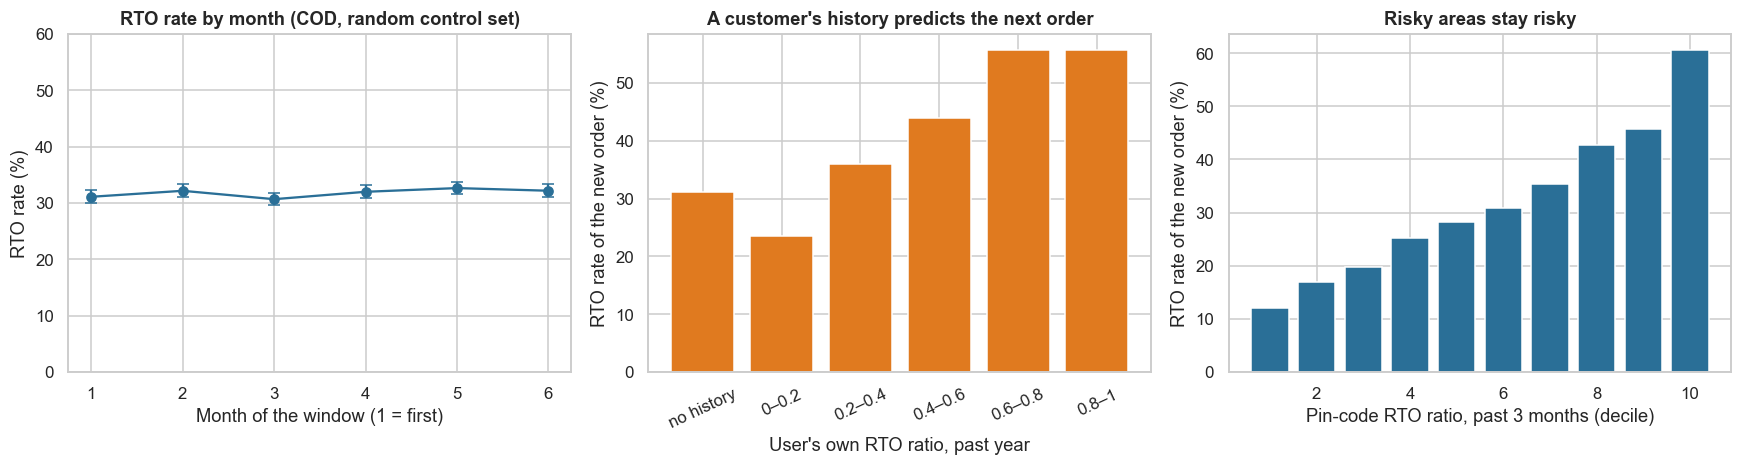

RTO rate by user-history bucket: {'no history': 31.1, '0–0.2': 23.6, '0.2–0.4': 36.0, '0.4–0.6': 44.0, '0.6–0.8': 55.7, '0.8–1': 55.7} | orders: {'no history': 8399, '0–0.2': 20026, '0.2–0.4': 3472, '0.4–0.6': 3299, '0.6–0.8': 1354, '0.8–1': 3450}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
mo = c.assign(month=np.minimum(c.day // 30, 5) + 1).groupby("month").rto.agg(["sum", "count"]); ci = np.array([proportion_confint(s, n, method="wilson") for s, n in zip(mo["sum"], mo["count"])]); m_ = mo["sum"] / mo["count"]
axes[0].errorbar(mo.index, m_ * 100, yerr=[(m_ - ci[:, 0]) * 100, (ci[:, 1] - m_) * 100], marker="o", color="#2a6f97", capsize=4); axes[0].set_ylim(0, 60); axes[0].set_xlabel("Month of the window (1 = first)"); axes[0].set_ylabel("RTO rate (%)"); axes[0].set_title("RTO rate by month (COD, random control set)")
LB = ["0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1"]; lab = pd.cut(c.user_rto_1y, [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0], labels=LB).astype(object).fillna("no history"); bb = c.assign(b=lab).groupby("b").rto.agg(["mean", "count"]).reindex(["no history"] + LB)
axes[1].bar([str(x) for x in bb.index], bb["mean"] * 100, color="#e07a1f"); axes[1].tick_params(axis="x", rotation=25); axes[1].set_xlabel("User's own RTO ratio, past year"); axes[1].set_ylabel("RTO rate of the new order (%)"); axes[1].set_title("A customer's history predicts the next order")
pq = pd.qcut(c.pin_rto_3m.rank(method="first"), 10, labels=False); pb = c.assign(q=pq).groupby("q").rto.mean() * 100; axes[2].bar(pb.index + 1, pb.values, color="#2a6f97"); axes[2].set_xlabel("Pin-code RTO ratio, past 3 months (decile)"); axes[2].set_ylabel("RTO rate of the new order (%)"); axes[2].set_title("Risky areas stay risky")
plt.tight_layout(); plt.show()
print("RTO rate by user-history bucket:", (bb["mean"] * 100).round(1).to_dict(), "| orders:", bb["count"].to_dict())

**Takeaway:** the user's own history is a strong, mostly rising signal. The RTO rate of the next order is **23.6%** for users with a past RTO ratio of 0 to 0.2, **36.0%** for 0.2 to 0.4, **44.0%** for 0.4 to 0.6 and **55.7%** for both 0.6 to 0.8 and 0.8 to 1 (so it flattens at the top). Users with **no history** sit at **31.1%** (8,399 orders), near the overall average, so history gives them no separation. The monthly and pin-code charts are read visually (no values are printed); the monthly rate looks fairly flat, which 7.1 tests formally. History features are the backbone of the model.

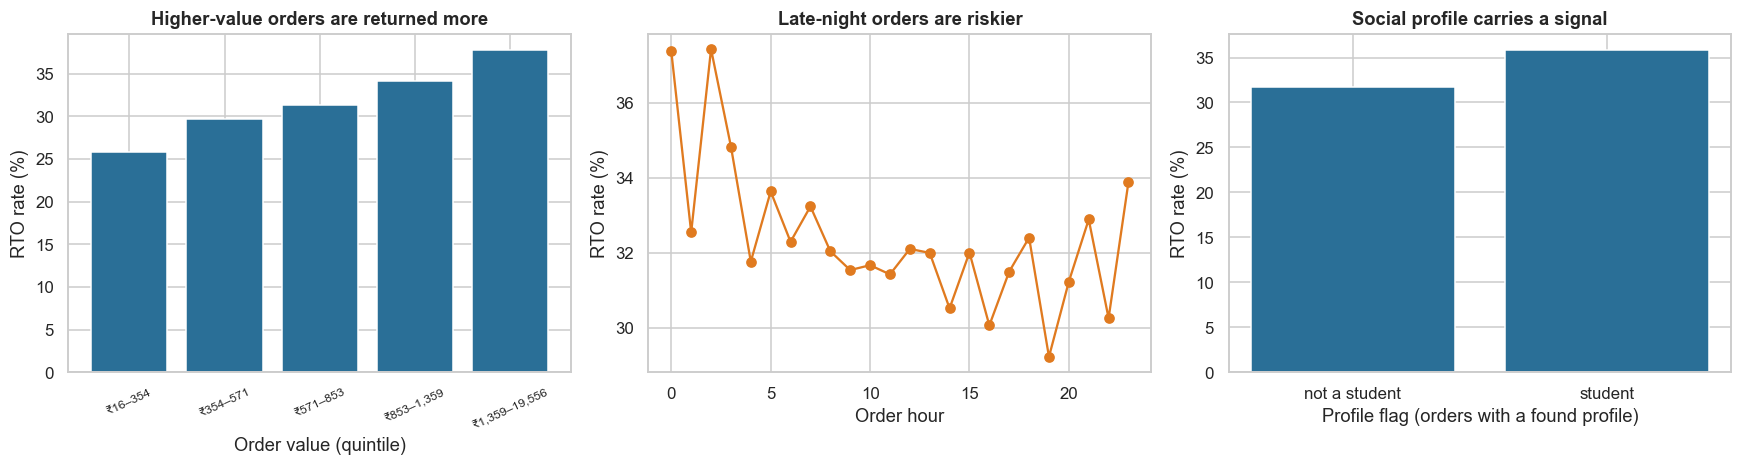

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
v = pd.qcut(c.order_value_inr, 5); vb = c.assign(v=v).groupby("v").rto.mean() * 100; axes[0].bar(range(5), vb.values, color="#2a6f97"); axes[0].set_xticks(range(5)); axes[0].set_xticklabels([f"₹{int(i.left):,}–{int(i.right):,}" for i in vb.index], rotation=25, fontsize=8); axes[0].set_xlabel("Order value (quintile)"); axes[0].set_ylabel("RTO rate (%)"); axes[0].set_title("Higher-value orders are returned more")
hh = c.assign(h=c.hour.fillna(15).astype(int)).groupby("h").rto.mean() * 100; axes[1].plot(hh.index, hh.values, marker="o", color="#e07a1f"); axes[1].set_xlabel("Order hour"); axes[1].set_ylabel("RTO rate (%)"); axes[1].set_title("Late-night orders are riskier")
s = c[c.found_profile == 1].assign(t=lambda d: d.is_student.map({1: "student", 0: "not a student"})).groupby("t").rto.mean() * 100; axes[2].bar(s.index, s.values, color="#2a6f97"); axes[2].set_xlabel("Profile flag (orders with a found profile)"); axes[2].set_ylabel("RTO rate (%)"); axes[2].set_title("Social profile carries a signal")
plt.tight_layout(); plt.show()

**Takeaway:** order value, hour and the social flag all show visible differences in RTO rate in the charts (exact values are not printed, so we do not quote them here). They are one-at-a-time views and mix effects: value, hour and occupation overlap with user history. The modelling in section 7 therefore judges what each feature group adds after controlling for the others, rather than relying on these bar charts.

## 7. Statistical Analysis (core section)

### 7.1 Why a randomised holdout: selection bias from intervened logs

**(a) Why?** The platform's earlier model blocks risky COD orders, so their outcome is **never observed**. A model trained on such logs sees only the orders that were allowed to ship. The paper therefore sets aside **5% of orders with no intervention**. Here we test that idea: we train the **same model** on (i) the randomised control set and (ii) the legacy-logged set, and score both on the control set's **last month** (an unbiased test).
- **H1:** H0: the two training sets give models with equal AUC, recall at the cap and calibration (PCOC) on random-control orders. **Bootstrap CIs** over test orders; a **z-test** compares the observed RTO rate of shipped legacy orders with the control set's rate.
- We also test **stability over time** (logistic trend of RTO on the day of the order).
- **Features used here:** order-history features only. The time split: first 150 days train, last 30 days test.

#### Code

In [8]:
TREND = ["user_rto_3m", "user_n_3m", "user_rto_1y", "user_n_1y", "pin_rto_3m", "pin_rto_1y", "seller_rto_3m", "seller_rto_1y", "cat_rto_3m", "cat_rto_1y"]
ORDER = ["hour", "weekday", "log_value"]; SOCQ = ["is_student", "n_jobs", "n_degrees", "friends", "followers", "years_working", "years_education"]; EMB = [f"emb_{k}" for k in range(8)]
G1 = TREND + ORDER; G2 = G1 + SOCQ + ["has_social"]; G3 = G2 + EMB; GROUPS = {"history only": G1, "+ social quantitative": G2, "+ social embedding": G3}
TAU = 0.6; CAP = 0.03; SPLIT = 150
def prep(d, tau=TAU):
    d = d.copy(); ok = (d.found_profile == 1) & (d.match_score >= tau); d["has_social"] = ok.astype(int); d["log_value"] = np.log(d.order_value_inr.clip(lower=50))
    for col in SOCQ + EMB: d.loc[~ok, col] = np.nan
    return d
c_raw = c.copy(); c = prep(c); leg = prep(leg); tr0 = c[c.day < SPLIT]; te0 = c[c.day >= SPLIT].reset_index(drop=True)
MED = {"hour": tr0.hour.median(), "log_value": tr0.log_value.median()}
def make_X(d, cols):
    Z = d[cols].copy()
    for k in cols: Z[k] = Z[k].fillna(MED[k]) if k in MED else Z[k].fillna(-1)
    return Z
def mk(name):
    if name == "RF": return RandomForestClassifier(n_estimators=200, min_samples_leaf=25, max_features="sqrt", n_jobs=4, random_state=SEED)
    if name == "HGB": return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50, early_stopping=True, random_state=SEED)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
def oof_threshold(name, X, y, cap=CAP):
    """Score threshold giving false-positive rate = cap on out-of-fold training predictions (4 folds)."""
    p = np.zeros(len(y))
    for a, b in StratifiedKFold(4, shuffle=True, random_state=SEED).split(X, y): p[b] = mk(name).fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1]
    return float(np.quantile(p[y == 0], 1 - cap)), p
def opm(y, flag):
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum()); P, N = int((y == 1).sum()), int((y == 0).sum()); fl = int(flag.sum())
    return dict(precision=tp / fl if fl else np.nan, recall=tp / P, fpr=fp / N, flagged=fl / len(y), goodness_bps=(y.mean() - y[~flag].mean()) * 1e4 if fl < len(y) else np.nan)
def boot(fn, n, B=500): return np.nanpercentile([fn(i) for i in (RNG.integers(0, n, n) for _ in range(B))], [2.5, 97.5])
# the same model trained on random control vs legacy-logged data
yte = te0.rto.values.astype(int); Xte1 = make_X(te0, G1); legtr = leg[(leg.day < SPLIT) & leg.rto.notna()]; rows = []
for name, d in (("randomised control set", tr0), ("legacy-logged (blocked orders unobserved)", legtr)):
    Xtr = make_X(d, G1); ytr = d.rto.values.astype(int); thr, _ = oof_threshold("HGB", Xtr, ytr); m = mk("HGB").fit(Xtr, ytr); p = m.predict_proba(Xte1)[:, 1]; fl = p > thr; o = opm(yte, fl)
    a_ci = boot(lambda i: roc_auc_score(yte[i], p[i]), len(yte)); r_ci = boot(lambda i: (fl[i] & (yte[i] == 1)).sum() / (yte[i] == 1).sum(), len(yte)); pc = p.sum() / yte.sum()
    rows.append((name, len(d), ytr.mean(), roc_auc_score(yte, p), *a_ci, o["recall"], *r_ci, o["fpr"], pc))
sb = pd.DataFrame(rows, columns=["training data", "train orders", "RTO rate in training labels", "test AUC", "AUC lo", "AUC hi", "recall at cap", "recall lo", "recall hi", "realised FPR", "PCOC (pred / obs)"]).set_index("training data"); print(sb.round(4).T.to_string())
obs_leg = legtr.rto.mean(); n_l = len(legtr); n_c = len(tr0); z = (obs_leg - tr0.rto.mean()) / np.sqrt(tr0.rto.mean() * (1 - tr0.rto.mean()) * (1 / n_l + 1 / n_c)); print(f"\nLegacy-logged observed RTO rate {obs_leg:.2%} vs control {tr0.rto.mean():.2%} (z = {z:.1f}, p = {2 * stats.norm.sf(abs(z)):.2g}); share of legacy orders blocked: {leg.legacy_blocked.mean():.1%}, of which true RTO had they shipped: {leg.loc[leg.legacy_blocked == 1, '_rto_if_shipped'].mean():.1%}")
lt = sm.Logit(c.rto, sm.add_constant(((c.day - 90) / 30).rename("month"))).fit(disp=0); print(f"Time trend in RTO rate: odds ratio per month {np.exp(lt.params['month']):.3f} (95% CI {np.exp(lt.conf_int().loc['month', 0]):.3f} to {np.exp(lt.conf_int().loc['month', 1]):.3f}), p = {lt.pvalues['month']:.2g}")

training data                randomised control set  legacy-logged (blocked orders unobserved)
train orders                            33,255.0000                                27,750.0000
RTO rate in training labels                  0.3170                                     0.2707
test AUC                                     0.7925                                     0.7870
AUC lo                                       0.7810                                     0.7773
AUC hi                                       0.8034                                     0.7987
recall at cap                                0.2374                                     0.2960
recall lo                                    0.2212                                     0.2785
recall hi                                    0.2549                                     0.3127
realised FPR                                 0.0278                                     0.0465
PCOC (pred / obs)                            1.003

**(c)/(f) Observation:** **(c)** Training on the legacy-logged data gives almost the same ranking quality: **AUC 0.7870** (CI 0.7773 to 0.7987) against **0.7925** (0.7810 to 0.8034) for the randomised control set, so the CIs overlap and we cannot separate them. The differences are elsewhere. The legacy model's training labels show an RTO rate of **27.1% against 31.7%** (z = -12.2, p = 1.9e-34), because **16.8%** of legacy orders were blocked and **56.2%** of those would have been RTO had they shipped. Its calibration is off (PCOC **0.971** vs **1.004**). Its recall at the cap is higher (**29.6%** vs **23.7%**), but its realised false-positive rate is **4.65%** against the 3% cap, while the control model realises **2.78%**; the extra recall is bought with extra false positives, because the cap was set on a training set missing the riskiest orders. The time trend is not significant: odds ratio **1.012 per month** (95% CI 1.000 to 1.024, p = 0.058). **(f)** Selection bias here distorts calibration and the false-positive cap more than AUC. The randomised holdout is what makes the cap reliable, and the data are stable enough over the window that a first-150-days / last-30-days split is fair.

### 7.2 Re-identification: how strict should the match threshold be?

**(a) Why?** The social features exist only for users whose public profile is found **and** matched with a score above a threshold. A low threshold covers more users but lets wrong people in; a high one is accurate but covers few. In the simulation we know whether each match is right (hidden `_true_match`), so we can measure **match precision** with a Wilson CI and see the effect on model accuracy.
- **H2:** H0: match precision does not change with the threshold. **Chi-square** across thresholds on the matched users.
- **Model effect:** gradient boosting with all features at each threshold; **test AUC** with bootstrap CI.

#### Code

Users: 10,963 | with a candidate profile: 5,514 (50.3%) | candidates that are the right person (hidden): 88.5%


           matched / found  matched / all users  match precision  prec. lo  prec. hi  orders with social features  test AUC (all features)  AUC lo  AUC hi
threshold                                                                                                                                                 
0.4000              0.9369               0.4712           0.9431    0.9364    0.9491                       0.4706                   0.8053  0.7949  0.8185
0.5000              0.9068               0.4561           0.9656    0.9602    0.9703                       0.4548                   0.8063  0.7966  0.8163
0.6000              0.8622               0.4336           0.9813    0.9770    0.9848                       0.4338                   0.8066  0.7965  0.8165
0.8000              0.5490               0.2761           0.9970    0.9944    0.9984                       0.2792                   0.8027  0.7916  0.8136
0.9000              0.2354               0.1184           1.0000    0.

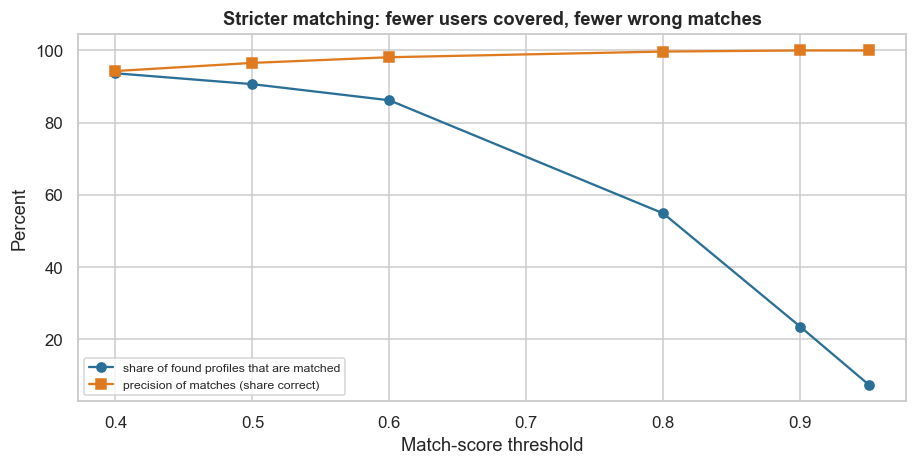

In [9]:
U = c.drop_duplicates("user_id")[["user_id", "found_profile", "match_score", "_true_match"]]; F = U[U.found_profile == 1]; rows = []; MS = {}
print(f"Users: {len(U):,} | with a candidate profile: {len(F):,} ({len(F) / len(U):.1%}) | candidates that are the right person (hidden): {(F._true_match == 1).mean():.1%}")
for tau in (0.4, 0.5, 0.6, 0.8, 0.9, 0.95):
    Mu = F[F.match_score >= tau]; prec = (Mu._true_match == 1).mean() if len(Mu) else np.nan; lo, hi = proportion_confint((Mu._true_match == 1).sum(), len(Mu), method="wilson") if len(Mu) else (np.nan, np.nan)
    ctau = prep(c_raw, tau); a_, b_ = ctau[ctau.day < SPLIT], ctau[ctau.day >= SPLIT].reset_index(drop=True); m = mk("HGB").fit(make_X(a_, G3), a_.rto.values.astype(int)); p = m.predict_proba(make_X(b_, G3))[:, 1]; yb = b_.rto.values.astype(int)
    rows.append((tau, len(Mu) / len(F), len(Mu) / len(U), prec, lo, hi, ctau.has_social.mean(), roc_auc_score(yb, p), *boot(lambda i: roc_auc_score(yb[i], p[i]), len(yb), 200)))
rs = pd.DataFrame(rows, columns=["threshold", "matched / found", "matched / all users", "match precision", "prec. lo", "prec. hi", "orders with social features", "test AUC (all features)", "AUC lo", "AUC hi"]).set_index("threshold"); print(rs.round(4).to_string())
tbl = pd.DataFrame({"right": [(F[F.match_score >= t]._true_match == 1).sum() for t in (0.4, 0.6, 0.8)], "wrong": [(F[F.match_score >= t]._true_match == 0).sum() for t in (0.4, 0.6, 0.8)]}); chi = stats.chi2_contingency(tbl.values)
print(f"Chi-square on right/wrong match counts at thresholds 0.4, 0.6, 0.8: chi2 = {chi[0]:.1f}, p = {chi[1]:.2g}")
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.plot(rs.index, rs["matched / found"] * 100, marker="o", label="share of found profiles that are matched", color="#2a6f97"); ax.plot(rs.index, rs["match precision"] * 100, marker="s", label="precision of matches (share correct)", color="#e07a1f"); ax.set_xlabel("Match-score threshold"); ax.set_ylabel("Percent"); ax.set_title("Stricter matching: fewer users covered, fewer wrong matches"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** **(c)** Match precision rises as the threshold tightens: **94.3%** at 0.4, **96.6%** at 0.5, **98.1%** at 0.6, **99.7%** at 0.8, and 100% at 0.9 and above, while the share of found profiles kept falls from **93.7%** to **86.2%** (at 0.6), **54.9%** (at 0.8) and **7.5%** (at 0.95). The chi-square on right/wrong counts at 0.4, 0.6 and 0.8 rejects equal precision (chi2 = 223.3, p = 3.3e-49). The model effect is small: test AUC is **0.8053** at 0.4, **0.8066** at 0.6 and **0.7920** at 0.95, and the CIs overlap heavily across 0.4 to 0.8. **(f)** A threshold near **0.6** keeps most of the coverage (43% of users matched) with 98% correct matches, and AUC is flat in that region, so there is no accuracy reason to accept the 6% wrong matches at 0.4. Only the very strict thresholds (0.9 and above) give up coverage and some AUC.

### 7.3 Model comparison across feature groups (time-ordered split)

**(a) Why?** The paper compares three feature sets and three models on the **last month**. We repeat the design on our data with three models: **logistic regression** (baseline), **Random Forest** and **gradient boosting** (our stand-in for XGBoost). Thresholds are set to a **3% false-positive rate** on **out-of-fold** training predictions (so the cap is not tuned on the test month), and test results are reported with **bootstrap CIs** over test orders. No hyper-parameter search.
- **H:** H0: the models have the same AUC. We report AUC, PR-AUC, recall at the cap and the realised false-positive rate.

#### Code

In [10]:
ytr0 = tr0.rto.values.astype(int); RES = {}; rows = []
t0 = time.time()
for mname in ("LR", "RF", "HGB"):
    for gname, cols in GROUPS.items():
        Xa, Xb = make_X(tr0, cols), make_X(te0, cols); thr, _ = oof_threshold(mname, Xa, ytr0); p = mk(mname).fit(Xa, ytr0).predict_proba(Xb)[:, 1]; fl = p > thr; o = opm(yte, fl); RES[(mname, gname)] = dict(p=p, flag=fl, thr=thr)
        rows.append((mname, gname, roc_auc_score(yte, p), *boot(lambda i: roc_auc_score(yte[i], p[i]), len(yte), 200), average_precision_score(yte, p), o["recall"], o["precision"], o["fpr"], o["goodness_bps"]))
mt = pd.DataFrame(rows, columns=["model", "features", "AUC", "AUC lo", "AUC hi", "PR-AUC", "recall at cap", "precision at cap", "realised FPR", "Goodness (bps)"]).set_index(["model", "features"]); print(f"Test month: {len(yte):,} orders, {yte.sum():,} RTO ({yte.mean():.1%}) | fitted {len(rows)} models in {time.time() - t0:.0f}s"); mt.round(4)

Test month: 6,745 orders, 2,169 RTO (32.2%) | fitted 9 models in 489s


AUC  AUC lo  AUC hi  PR-AUC  recall at cap  precision at cap  realised FPR  Goodness (bps)
model features                                                                                                           
LR    history only          0.7580  0.7460  0.7708  0.6087         0.1978            0.7513        0.0310        397.4452
      + social quantitative 0.7805  0.7694  0.7914  0.6401         0.2310            0.7696        0.0328        478.5969
      + social embedding    0.7804  0.7698  0.7911  0.6396         0.2324            0.7718        0.0326        482.6228
RF    history only          0.7866  0.7769  0.7967  0.6518         0.2370            0.7944        0.0291        501.7108
      + social quantitative 0.7987  0.7865  0.8088  0.6649         0.2490            0.8012        0.0293        532.4671
      + social embedding    0.7985  0.7882  0.8101  0.6635         0.2467            0.7938        0.0304        524.2312
HGB   history only          0.7925  0.7814  0.8029  0.6607         0.2374            0.8022        0.0278        505.5728
      + social quantitative 0.8052  0.7949  0.8153  0.6734         0.2513            0.8110        0.0278        541.5839
      + social embedding    0.8066  0.7976  0.8181  0.6769         0.2591            0.8157        0.0278        562.1486

**(c)/(f) Observation:** **(c)** Gradient boosting has the highest AUC family (**0.8066** with all features), Random Forest is close (**0.7987** with quantitative social features, 0.7985 with the embedding) and logistic regression is lowest (**0.7580** history only, 0.7805 and 0.7804 with social features). The CIs of the tree models overlap, so Random Forest and gradient boosting are not clearly different; logistic regression with history only is clearly below both. Social features raise AUC in every family: **+0.0225** for logistic regression (history to quantitative), **+0.0121** for Random Forest and **+0.0127** for gradient boosting. The embedding adds nothing for logistic regression and Random Forest, and **+0.0014** for gradient boosting. Recall at the cap ranges from **19.8%** to **25.9%** and the realised false-positive rate stays between **2.8% and 3.3%**, so the cap is held on the unseen month. **(f)** Non-linear trees on history features are worth about **0.03 AUC** over logistic regression. The social gain is smaller than the model-family gain on all orders, but it adds on top of it.

### 7.4 Does social data add value? Paired tests (all orders, re-identified subset, thin-history subset)

**(a) Why?** The three feature groups are scored on the **same test orders**, so the comparisons are paired. For the best model family we test, for each step (history → + social quantitative → + embedding) and for the first-to-last step:
- **ΔAUC** with a **paired bootstrap** (500 resamples of test orders);
- **Δrecall at the cap** with a paired bootstrap and **McNemar's exact test** on the RTO orders (flagged by one model but not the other); **Holm** over the comparisons in each subset;
- ΔGoodness with a paired bootstrap.

The subsets are: all test orders; orders of **re-identified users** (the paper's population); and **thin-history users** (at most one past order in a year), where social data should matter most.

#### Code

In [11]:
best_m = mt.groupby("model")["AUC"].max().idxmax(); print("Model family with the highest AUC (best feature group):", best_m)
subsets = {"all test orders": np.ones(len(yte), bool), "re-identified users only": te0.has_social.values == 1, "thin history (user_n_1y ≤ 1)": (te0.user_n_1y.values <= 1)}
pairs = [("history only", "+ social quantitative"), ("+ social quantitative", "+ social embedding"), ("history only", "+ social embedding")]; rows = []
for sname, mask in subsets.items():
    idx0 = np.where(mask)[0]; y0 = yte[idx0]; sub_rows = []
    for a, b in pairs:
        pa, pb = RES[(best_m, a)]["p"][idx0], RES[(best_m, b)]["p"][idx0]; fa, fb = RES[(best_m, a)]["flag"][idx0], RES[(best_m, b)]["flag"][idx0]
        dauc = roc_auc_score(y0, pb) - roc_auc_score(y0, pa); drec = fb[y0 == 1].mean() - fa[y0 == 1].mean(); dgood = opm(y0, fb)["goodness_bps"] - opm(y0, fa)["goodness_bps"]
        bs = [(roc_auc_score(y0[i], pb[i]) - roc_auc_score(y0[i], pa[i]), fb[i][y0[i] == 1].mean() - fa[i][y0[i] == 1].mean(), opm(y0[i], fb[i])["goodness_bps"] - opm(y0[i], fa[i])["goodness_bps"]) for i in (RNG.integers(0, len(y0), len(y0)) for _ in range(500))]
        bs = np.array(bs); pos = y0 == 1; n10, n01 = int((fb[pos] & ~fa[pos]).sum()), int((fa[pos] & ~fb[pos]).sum()); pm = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 >= 1 else np.nan
        sub_rows.append([sname, f"{a} → {b}", len(y0), dauc, *np.percentile(bs[:, 0], [2.5, 97.5]), drec, *np.percentile(bs[:, 1], [2.5, 97.5]), n10, n01, pm, dgood, *np.percentile(bs[:, 2], [2.5, 97.5])])
    ph = multipletests([1.0 if np.isnan(r[11]) else r[11] for r in sub_rows], method="holm")[1]
    for r, p_ in zip(sub_rows, ph): rows.append(r + [p_])
pt = pd.DataFrame(rows, columns=["subset", "step", "orders", "ΔAUC", "AUC lo", "AUC hi", "Δrecall", "rec lo", "rec hi", "RTO caught only by new", "caught only by old", "McNemar p", "ΔGoodness (bps)", "good lo", "good hi", "p_holm"]).set_index(["subset", "step"]); pt.round(4)

Model family with the highest AUC (best feature group): HGB


orders   ΔAUC  AUC lo  AUC hi  Δrecall  rec lo  rec hi  RTO caught only by new  \
subset                       step                                                                                                                         
all test orders              history only → + social quantitative          6745 0.0127  0.0085  0.0170   0.0138  0.0030  0.0254                     100   
                             + social quantitative → + social embedding    6745 0.0014  0.0001  0.0027   0.0078  0.0000  0.0147                      45   
                             history only → + social embedding             6745 0.0141  0.0099  0.0182   0.0217  0.0096  0.0330                     110   
re-identified users only     history only → + social quantitative          2915 0.0305  0.0216  0.0389   0.0421  0.0201  0.0633                      85   
                             + social quantitative → + social embedding    2915 0.0021 -0.0005  0.0046   0.0144 -0.0005  0.0282                      30   
                             history only → + social embedding             2915 0.0325  0.0234  0.0420   0.0565  0.0321  0.0813                      97   
thin history (user_n_1y ≤ 1) history only → + social quantitative          2991 0.0194  0.0119  0.0276   0.0248  0.0089  0.0440                      55   
                             + social quantitative → + social embedding    2991 0.0014 -0.0010  0.0035   0.0186  0.0063  0.0297                      27   
                             history only → + social embedding             2991 0.0208  0.0134  0.0283   0.0435  0.0259  0.0619                      64   

                                                                         caught only by old  McNemar p  ΔGoodness (bps)  good lo  good hi  p_holm  
subset                       step                                                                                                                  
all test orders              history only → + social quantitative                        70     0.0258          36.0112   7.1385  66.5704  0.0517  
                             + social quantitative → + social embedding                  28     0.0604          20.5647  -0.4930  41.2368  0.0604  
                             history only → + social embedding                           63     0.0004          56.5758  23.5442  86.7831  0.0013  
re-identified users only     history only → + social quantitative                        44     0.0004         109.6001  46.9813 170.9189  0.0008  
                             + social quantitative → + social embedding                  16     0.0541          39.3444  -2.1851  76.2710  0.0541  
                             history only → + social embedding                           42     0.0000         148.9445  83.6062 217.1175  0.0000  
thin history (user_n_1y ≤ 1) history only → + social quantitative                        31     0.0127          59.1736  15.0435 110.0802  0.0127  
                             + social quantitative → + social embedding                   9     0.0039          48.1820  14.8786  79.3858  0.0079  
                             history only → + social embedding                           22     0.0000         107.3556  64.9790 156.1186  0.0000

**(c)/(f) Observation:** **(c)** For gradient boosting on all test orders, adding the quantitative social features raises AUC by **0.0127** (CI 0.0085 to 0.0170) and recall by **1.4 points** (CI 0.3 to 2.5), with 100 RTO orders caught only by the new model and 70 only by the old (McNemar p = 0.026, Holm p = 0.052). The embedding step alone is borderline: ΔAUC **0.0014** (CI 0.0001 to 0.0027), p_holm = 0.060. From history only to the full model, the gain is **ΔAUC 0.0141**, **Δrecall +2.2 points** (0.96 to 3.30; 110 vs 63 orders; p_holm = **0.0013**) and **+56.6 bps** of Goodness (CI 23.5 to 86.8). For **re-identified users** the gain is larger: **ΔAUC 0.0325** (CI 0.0234 to 0.0420), **Δrecall +5.7 points** (CI 3.2 to 8.1), 97 vs 42 orders, p_holm < 1e-4 and **+148.9 bps** Goodness. For **thin-history users** (at most one past order): **ΔAUC 0.0208**, **Δrecall +4.4 points** and +107.4 bps, p_holm < 1e-4; here the embedding step is also significant by recall (+1.9 points, p_holm = 0.0079) though its ΔAUC CI includes zero. **(f)** Social data is clearly useful, but the benefit sits with re-identified and thin-history users; for all orders the gain is about 1.4 points of AUC and 2 points of recall. The embedding adds little beyond the quantitative profile features and should not be used on its own as the reason to collect text data.

### 7.5 The operating point: Goodness, calibration and sensitivity to the cap

**(a) Why?** One model and one threshold are needed at checkout. We take the Random Forest or gradient boosting with all features (whichever the 7.3 table shows with the higher AUC on that group), report precision, recall, false-positive rate and **Goodness** at the 3% cap with **bootstrap CIs**, show the **cap sensitivity** (1% to 10%) and test **calibration** (calibration slope and **Hosmer–Lemeshow**), since the cost rule in 7.7 uses the predicted probabilities.
- **H4:** H0: calibrated (slope = 1; HL p > 0.05).

#### Code

Final model: HGB with all features | cap 3% | threshold 0.674
              estimate   CI low  CI high
precision       0.8157   0.7901   0.8432
recall          0.2591   0.2425   0.2790
fpr             0.0278   0.0236   0.0325
flagged         0.1021      NaN      NaN
goodness_bps  562.1486 510.7266 613.7532



         recall  precision  realised FPR  share of orders flagged  Goodness (bps)
FPR cap                                                                          
0.0100   0.1374     0.8791        0.0090                   0.0503        295.0160
0.0200   0.2089     0.8420        0.0186                   0.0798        451.0948
0.0300   0.2591     0.8157        0.0278                   0.1021        562.1486
0.0500   0.3338     0.7743        0.0461                   0.1386        728.6241
0.1000   0.4601     0.6897        0.0981                   0.2145      1,005.4473

Calibration slope 1.106 (95% CI 1.046 to 1.165), intercept +0.051 | PCOC 1.005 | Hosmer–Lemeshow chi2 = 22.9 (df 8), p = 0.00348


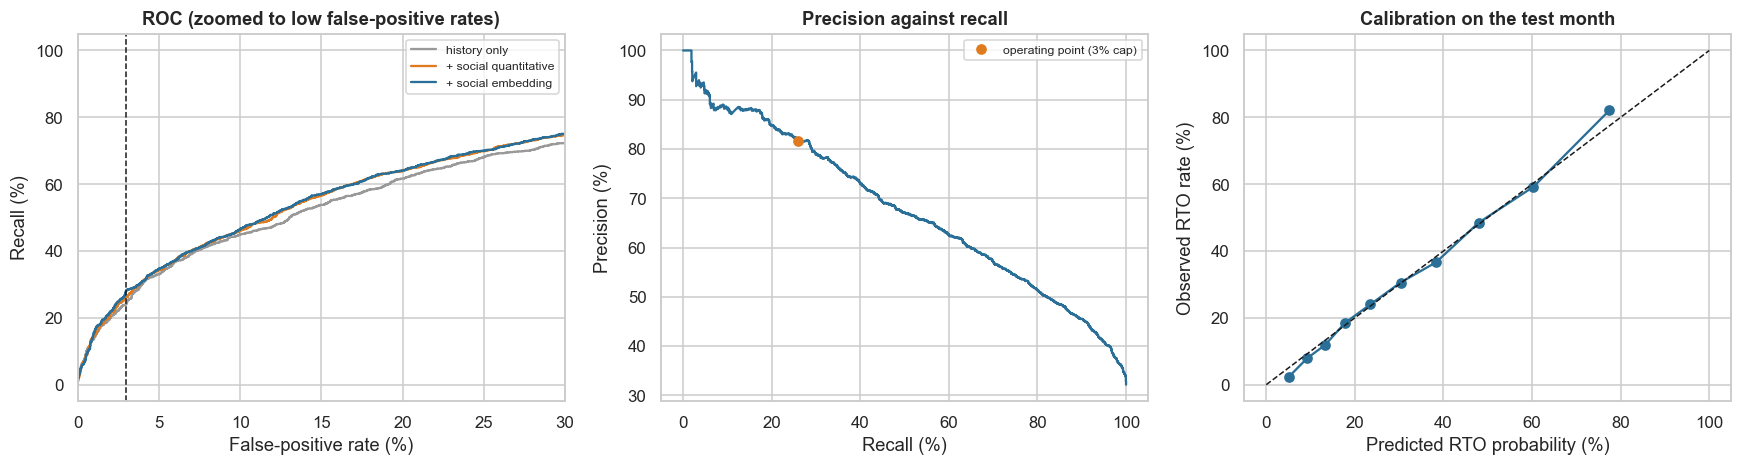

In [12]:
fam = max(("RF", "HGB"), key=lambda mname: mt.loc[(mname, "+ social embedding"), "AUC"]); R = RES[(fam, "+ social embedding")]; pF = R["p"]; flF = R["flag"]; o = opm(yte, flF)
cis = {k: boot(lambda i, k=k: opm(yte[i], flF[i])[k], len(yte), 500) for k in ("precision", "recall", "fpr", "goodness_bps")}
print(f"Final model: {fam} with all features | cap {CAP:.0%} | threshold {R['thr']:.3f}")
print(pd.DataFrame({"estimate": o, "CI low": {k: v[0] for k, v in cis.items()} | {"flagged": np.nan}, "CI high": {k: v[1] for k, v in cis.items()} | {"flagged": np.nan}}).round(4).to_string())
Xa, Xb = make_X(tr0, G3), make_X(te0, G3); rows = []; _, poof = oof_threshold(fam, Xa, ytr0)
for cap in (0.01, 0.02, 0.03, 0.05, 0.10):
    thr = float(np.quantile(poof[ytr0 == 0], 1 - cap)); oo = opm(yte, pF > thr); rows.append((cap, oo["recall"], oo["precision"], oo["fpr"], oo["flagged"], oo["goodness_bps"]))
cp = pd.DataFrame(rows, columns=["FPR cap", "recall", "precision", "realised FPR", "share of orders flagged", "Goodness (bps)"]).set_index("FPR cap"); print(); print(cp.round(4).to_string())
z_ = np.log(np.clip(pF, 1e-6, 1 - 1e-6) / (1 - np.clip(pF, 1e-6, 1 - 1e-6))); cf = sm.Logit(yte, sm.add_constant(z_)).fit(disp=0); q = pd.qcut(pF, 10, duplicates="drop"); gg = pd.DataFrame({"p": pF, "y": yte, "q": q}).groupby("q"); hl = (((gg.y.sum() - gg.p.sum()) ** 2) / (gg.p.sum() * (1 - gg.p.mean()))).sum(); df_ = gg.ngroups - 2
print(f"\nCalibration slope {cf.params[1]:.3f} (95% CI {cf.conf_int()[1, 0]:.3f} to {cf.conf_int()[1, 1]:.3f}), intercept {cf.params[0]:+.3f} | PCOC {pF.sum() / yte.sum():.3f} | Hosmer–Lemeshow chi2 = {hl:.1f} (df {df_}), p = {stats.chi2.sf(hl, df_):.3g}")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for gname, c_ in zip(GROUPS, ("#999999", "#e07a1f", "#2a6f97")):
    p_ = RES[(fam, gname)]["p"]; fpr, tpr, _ = roc_curve(yte, p_); axes[0].plot(fpr * 100, tpr * 100, label=gname, color=c_)
axes[0].axvline(CAP * 100, color="k", ls="--", lw=1); axes[0].set_xlim(0, 30); axes[0].set_xlabel("False-positive rate (%)"); axes[0].set_ylabel("Recall (%)"); axes[0].set_title("ROC (zoomed to low false-positive rates)"); axes[0].legend(fontsize=8)
pr, rc, _ = precision_recall_curve(yte, pF); axes[1].plot(rc * 100, pr * 100, color="#2a6f97"); axes[1].plot(o["recall"] * 100, o["precision"] * 100, "o", color="#e07a1f", label="operating point (3% cap)"); axes[1].set_xlabel("Recall (%)"); axes[1].set_ylabel("Precision (%)"); axes[1].set_title("Precision against recall"); axes[1].legend(fontsize=8)
axes[2].plot(gg.p.mean() * 100, gg.y.mean() * 100, marker="o", color="#2a6f97"); axes[2].plot([0, 100], [0, 100], "k--", lw=1); axes[2].set_xlabel("Predicted RTO probability (%)"); axes[2].set_ylabel("Observed RTO rate (%)"); axes[2].set_title("Calibration on the test month")
plt.tight_layout(); plt.show()

**Takeaway:** at the 3% cap the final model (gradient boosting, all features; threshold 0.674) flags **10.2%** of orders with **precision 81.6%** (CI 79.0% to 84.3%), **recall 25.9%** (CI 24.3% to 27.9%), a false-positive rate of **2.78%** (CI 2.36% to 3.25%) and Goodness of **562 bps** (CI 511 to 614). Cap sensitivity: at 1% the recall is **13.7%** (precision 87.9%), at 5% it is **33.4%** (77.4%) and at 10% it is **46.0%** (69.0%), so recall rises quickly as customer friction rises. Calibration is not perfect: the slope is **1.106** (CI 1.046 to 1.165; the model is slightly under-confident, so true risk varies a bit more than predicted), intercept +0.051, PCOC **1.005**, and Hosmer-Lemeshow **rejects** (chi2 = 22.9, df 8, p = 0.0035). With 6,745 test orders the test can detect small misfit, but the cost rule in 7.7 relies on these probabilities, so recalibration (for example isotonic) should be applied before using it. The recall of 25.9% is below the paper's reported 40% to 60%. We did not tune the simulation to match it.

### 7.6 Fairness and proxy risk: who gets flagged?

**(a) Why?** Social-profile features can act as **proxies** for occupation or income. The model never sees the hidden occupation type, but we can check whether **false positives** (good customers wrongly flagged) are spread **unequally** across types, and between users with and without a re-identified profile. A flag costs a good customer a prepayment demand or a call.
- **H5:** H0: false-positive rate is equal across occupation types (**chi-square** on good orders). Per-type **Wilson CIs**; pairwise comparison with the lowest group (**Fisher**, Holm).
- Also: flag rate and false-positive rate for re-identified vs other users, for the final model and for the history-only model.

#### Code

Chi-square across occupation types on good orders: chi2 = 11.5, p = 0.042 | lowest-FPR group: senior manager
                          good orders  FPR (final model)  FPR lo  FPR hi  FPR (history only)  flag rate  RTO rate
occupation type (hidden)                                                                                         
student                           607             0.0346  0.0227  0.0523              0.0346     0.1450    0.3624
early career                     1172             0.0239  0.0166  0.0343              0.0230     0.1036    0.3438
mid-career professional          1083             0.0212  0.0142  0.0317              0.0212     0.0635    0.2362
self-employed / business          742             0.0350  0.0240  0.0508              0.0350     0.1021    0.3297
senior manager                    418             0.0144  0.0066  0.0310              0.0263     0.0495    0.2330
other / not stated                554             0.0415  0.0278  0.0615              0.0343 

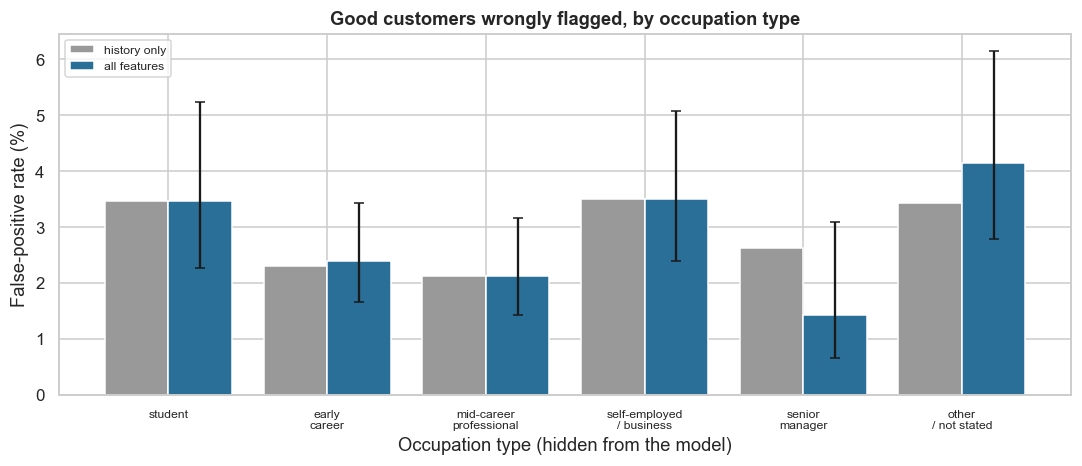

In [13]:
tn = te0.assign(flag=flF, flag_h=RES[(fam, "history only")]["flag"], y=yte); good = tn[tn.y == 0]; rows = []
for k, nm in enumerate(gen.TYPE_NAMES):
    g = good[good._type == k]; fp = int(g.flag.sum()); lo, hi = proportion_confint(fp, len(g), method="wilson"); gh = int(g.flag_h.sum()); rows.append((nm, len(g), fp / len(g), lo, hi, gh / len(g), tn[tn._type == k].flag.mean(), tn[tn._type == k].y.mean()))
ft = pd.DataFrame(rows, columns=["occupation type (hidden)", "good orders", "FPR (final model)", "FPR lo", "FPR hi", "FPR (history only)", "flag rate", "RTO rate"]).set_index("occupation type (hidden)")
chi = stats.chi2_contingency(pd.crosstab(good._type, good.flag).values); ref = ft["FPR (final model)"].idxmin(); pw = []
for k, nm in enumerate(gen.TYPE_NAMES):
    if nm == ref: continue
    a = good[good._type == k]; b = good[good._type == gen.TYPE_NAMES.index(ref)]; pw.append((nm, stats.fisher_exact([[a.flag.sum(), len(a) - a.flag.sum()], [b.flag.sum(), len(b) - b.flag.sum()]])[1]))
pw = pd.DataFrame(pw, columns=["type vs lowest-FPR group", "Fisher p"]).set_index("type vs lowest-FPR group"); pw["p_holm"] = multipletests(pw["Fisher p"], method="holm")[1]
print(f"Chi-square across occupation types on good orders: chi2 = {chi[0]:.1f}, p = {chi[1]:.2g} | lowest-FPR group: {ref}"); print(ft.round(4).to_string()); print(); print(pw.round(4).to_string())
g2 = tn.groupby("has_social").apply(lambda d: pd.Series({"orders": len(d), "flag rate": d.flag.mean(), "RTO rate": d.y.mean(), "FPR": d.flag[d.y == 0].mean(), "recall": d.flag[d.y == 1].mean()})); print(); print(g2.round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 4.4)); xs = np.arange(len(ft)); ax.bar(xs - 0.2, ft["FPR (history only)"] * 100, 0.4, label="history only", color="#999999"); ax.bar(xs + 0.2, ft["FPR (final model)"] * 100, 0.4, label="all features", color="#2a6f97", yerr=[(ft["FPR (final model)"] - ft["FPR lo"]) * 100, (ft["FPR hi"] - ft["FPR (final model)"]) * 100], capsize=3)
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" ", "\n", 1) for n in ft.index], fontsize=8); ax.set_xlabel("Occupation type (hidden from the model)"); ax.set_ylabel("False-positive rate (%)"); ax.set_title("Good customers wrongly flagged, by occupation type"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** the omnibus test across occupation types rejects equal false-positive rates (**chi2 = 11.5, p = 0.042**, 5 df), but weakly: **senior managers** are wrongly flagged least (**1.44%**, CI 0.66% to 3.10%) and **other / not stated** most (**4.15%**), then self-employed (3.50%), students (3.46%), early career (2.39%) and mid-career professionals (2.12%). No pairwise comparison with the lowest group survives Holm correction (smallest p_holm **0.067**, other / not stated), and the CIs overlap widely, so the evidence is suggestive rather than conclusive (the senior-manager group has only 418 good orders). Flag rates follow each group's RTO rate (for example 14.5% for students and for other / not stated, which have RTO rates of 36.2% and 40.9%, against 6.4% for mid-career professionals at 23.6%). The social features change the gap only for senior managers (FPR 2.63% history only, 1.44% with all features). Users with a re-identified profile have a flag rate of **11.3%** against **9.4%**, a lower false-positive rate (**2.58%** vs 2.92%) and higher recall (**28.5%** vs 23.8%). The model never sees occupation type, so any difference here comes through proxy features and history. Audit these gaps on real data before launch.

### 7.7 Cost-based threshold and the size of the A/B test

**(a) Why?** A cap protects customers but ignores money. Let a flagged order be **nudged to prepay or verify**. We assume (D-25-07): an RTO costs **₹180** (two-way shipping plus handling); the nudge **prevents** an RTO order's loss with probability **ρ = 50%**; a flagged good order is **lost with probability φ = 25%** at a contribution margin of **12% of order value**. The **expected net saving** of flagging an order with risk *p* is p·ρ·180 − (1 − p)·φ·0.12·value, so the rule is: flag if this is positive. We compare (i) no model, (ii) the 3% capped threshold and (iii) the cost-optimal rule (using calibrated probabilities), by **realised net ₹ per 1,000 orders** on the test month with bootstrap CIs, then give the **A/B sample size**.
- **H6:** H0: the net saving per order is equal for the capped and cost-optimal thresholds (**paired bootstrap**).
- **Sample size:** the RTO rate among flagged orders without the nudge versus with it (rate × (1 − ρ)), **two-proportion** test, 80% power, α = 0.05, for ρ of 20%, 35% and 50%.

#### Code

                           share flagged  recall  precision    FPR  net saving per 1,000 orders (₹)      CI low     CI high
policy                                                                                                                     
no model                          0.0000  0.0000        NaN 0.0000                           0.0000      0.0000      0.0000
capped threshold (3% FPR)         0.1020  0.2590     0.8160 0.0280                       6,768.4760  6,146.1330  7,426.3520
cost-optimal rule                 0.6280  0.8500     0.4350 0.5230                      17,689.1120 16,628.7100 18,760.7020



Cost-optimal minus capped: ₹10,921 per 1,000 orders (95% CI 10,024 to 11,854); paired t p = 3.8e-106

Net ₹ per 1,000 orders of the capped threshold, by effect and loss assumptions:
            φ = 10%    φ = 25%    φ = 40%
ρ = 30%  4,207.0000 3,769.0000 3,331.0000
ρ = 50%  7,207.0000 6,768.0000 6,330.0000
ρ = 70% 10,206.0000 9,768.0000 9,330.0000

A/B test size (flag share and precision from the capped model):
                            RTO rate, flagged, no nudge  RTO rate, flagged, nudge  flagged orders per arm  total COD orders needed (both arms)
RTO reduction by the nudge                                                                                                                    
20%                                              0.8160                    0.6530                     112                                 2193
35%                                              0.8160                    0.5300                      39                                  764
50%         

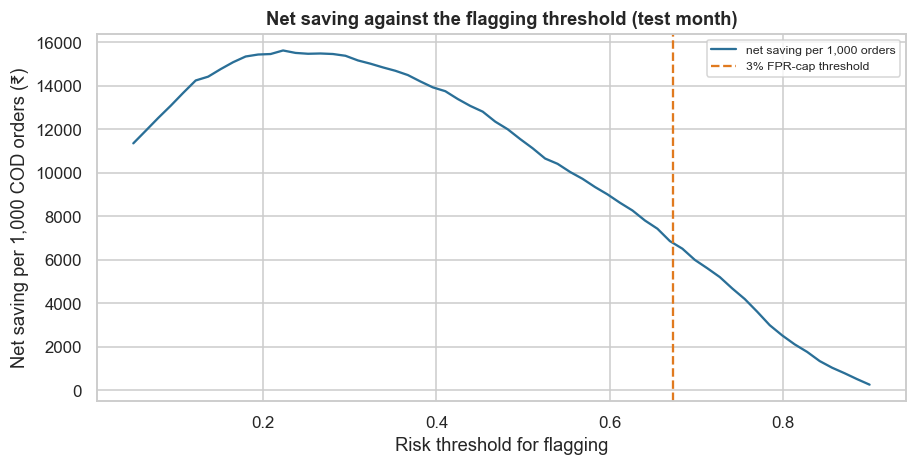

In [14]:
CRTO, RHO, PHI, MARG = 180.0, 0.50, 0.25, 0.12; val = te0.order_value_inr.fillna(te0.order_value_inr.median()).values
def net(flag, rho=RHO, phi=PHI): return (flag & (yte == 1)) * rho * CRTO - (flag & (yte == 0)) * phi * MARG * val
gain_p = pF * RHO * CRTO - (1 - pF) * PHI * MARG * val; fl_cost = gain_p > 0; none = np.zeros(len(yte), bool)
pol = {"no model": none, "capped threshold (3% FPR)": flF, "cost-optimal rule": fl_cost}; rows = []
for k, fl in pol.items():
    nt = net(fl); o_ = opm(yte, fl) if fl.any() else dict(precision=np.nan, recall=0, fpr=0, flagged=0, goodness_bps=0); lo, hi = boot(lambda i: net(fl)[i].mean() * 1000, len(yte), 500); rows.append((k, o_["flagged"], o_["recall"], o_["precision"], o_["fpr"], nt.mean() * 1000, lo, hi))
cst = pd.DataFrame(rows, columns=["policy", "share flagged", "recall", "precision", "FPR", "net saving per 1,000 orders (₹)", "CI low", "CI high"]).set_index("policy"); print(cst.round(3).to_string())
d = net(fl_cost) - net(flF); lo, hi = np.percentile([d[i].mean() * 1000 for i in (RNG.integers(0, len(d), len(d)) for _ in range(500))], [2.5, 97.5]); print(f"\nCost-optimal minus capped: ₹{d.mean() * 1000:,.0f} per 1,000 orders (95% CI {lo:,.0f} to {hi:,.0f}); paired t p = {stats.ttest_1samp(d, 0).pvalue:.2g}")
grid = pd.DataFrame({f"φ = {ph:.0%}": {f"ρ = {rh:.0%}": net(flF, rh, ph).mean() * 1000 for rh in (0.3, 0.5, 0.7)} for ph in (0.10, 0.25, 0.40)}); print("\nNet ₹ per 1,000 orders of the capped threshold, by effect and loss assumptions:"); print(grid.round(0).to_string())
prec_f = o["precision"]; rows = []
for rho in (0.20, 0.35, 0.50):
    p1, p2 = prec_f, prec_f * (1 - rho); n_arm = int(np.ceil((1.96 + 0.84) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2)); rows.append((f"{rho:.0%}", p1, p2, n_arm, int(np.ceil(n_arm * 2 / o["flagged"]))))
ss = pd.DataFrame(rows, columns=["RTO reduction by the nudge", "RTO rate, flagged, no nudge", "RTO rate, flagged, nudge", "flagged orders per arm", "total COD orders needed (both arms)"]).set_index("RTO reduction by the nudge"); print("\nA/B test size (flag share and precision from the capped model):"); print(ss.round(3).to_string())
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ths = np.linspace(0.05, 0.9, 60); nn = [net(pF > t).mean() * 1000 for t in ths]; fr = [(pF > t).mean() for t in ths]; ax.plot(ths, nn, color="#2a6f97", label="net saving per 1,000 orders"); ax.axvline(R["thr"], color="#e07a1f", ls="--", label="3% FPR-cap threshold"); ax.set_xlabel("Risk threshold for flagging"); ax.set_ylabel("Net saving per 1,000 COD orders (₹)"); ax.set_title("Net saving against the flagging threshold (test month)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** in the base case (RTO cost ₹180, nudge success ρ = 50%, loss φ = 25% of flagged good orders, 12% margin) the **capped threshold saves ₹6,768 per 1,000 orders** (CI 6,146 to 7,426) and the **cost-optimal rule ₹17,689** (CI 16,629 to 18,761), a difference of **₹10,921** per 1,000 orders (CI 10,024 to 11,854; p = 3.8e-106). The cost rule gets there by flagging **62.8%** of orders, with recall **85%** but precision only **43.5%** and a false-positive rate of **52.3%**; that is nudging more than half of all good COD customers, which the cost formula treats as a 25% loss each time and does not capture beyond that (repeat purchases, brand damage). The capped saving stays positive across the whole grid, from **₹3,331** (ρ 30%, φ 40%) to **₹10,206** (ρ 70%, φ 10%). **A/B size:** the capped model flags about 10.2% of orders with 81.6% RTO among them, so to detect a nudge that cuts RTO among flagged orders by **20%** we need 112 flagged orders per arm and **2,193 COD orders** in total, by **35%** 39 per arm (**764** orders) and by **50%** 19 per arm (**373** orders). These numbers cover only the RTO outcome; measuring the loss of good orders (φ) as a second outcome needs a larger sample, because it is a rate among about 90% of the orders.

## 8. ML Section — what we built and what is beyond it

- **Trees on tabular features** are the right default (consistent with the paper, where Random Forest beat TabNet). We did not tune hyper-parameters; fixed settings per the brief.
- **The model's job is a probability**, not a rank: the cost rule needs calibrated risk. A Random Forest's scores can be compressed or stretched; check calibration (7.5) and recalibrate with isotonic regression if needed.
- **History features are the backbone**; social data is a supplement that mostly helps users whose own history is thin. The paper's text embeddings (S-BERT with UMAP) are replaced by a simulated low-dimension vector here, since no real text exists.
- **Beyond this notebook:** address-quality scores and pin-code serviceability, a seller-level model, an uplift model for **which** orders respond to a nudge (we assumed one effect ρ), and an exploration slice for continuous retraining.

## 9. Business Translation — ₹ impact

Assumptions (D-25-07): **1 lakh COD orders a day** on the platform, 32% RTO (as documented in the study's data; the platform-wide rate is not known), ₹180 per RTO order, nudge effect ρ and good-order loss φ as below, 12% margin. The flag share, precision and recall are the capped model's from the test month; scenarios vary the nudge effect and loss: **worst** = ρ 30%, φ 40%; **base** = ρ 50%, φ 25%; **best** = ρ 70%, φ 10%. The CI uses the bootstrap over test orders.

#### Code

In [15]:
ORD_DAY = 1e5; rows = []
for nm, rho, phi in (("worst (ρ 30%, φ 40%)", 0.30, 0.40), ("base (ρ 50%, φ 25%)", 0.50, 0.25), ("best (ρ 70%, φ 10%)", 0.70, 0.10)):
    for pn, fl in (("capped (3% FPR)", flF), ("cost-optimal rule", (pF * rho * CRTO - (1 - pF) * phi * MARG * val) > 0)):
        v = net(fl, rho, phi); lo, hi = boot(lambda i: net(fl, rho, phi)[i].mean(), len(yte), 300)
        rows.append((nm, pn, v.mean() * 1000, v.mean() * ORD_DAY * 365 / 1e7, lo * ORD_DAY * 365 / 1e7, hi * ORD_DAY * 365 / 1e7, fl.mean()))
money = pd.DataFrame(rows, columns=["scenario", "policy", "net ₹ per 1,000 orders", "₹ crore / year", "CI low", "CI high", "share flagged"]).set_index(["scenario", "policy"]); money.round(3)

net ₹ per 1,000 orders  ₹ crore / year   CI low  CI high  share flagged
scenario             policy                                                                                    
worst (ρ 30%, φ 40%) capped (3% FPR)                3,330.6730         12.1570  10.5160  13.7870         0.1020
                     cost-optimal rule              6,243.5940         22.7890  20.4530  25.5600         0.3640
base (ρ 50%, φ 25%)  capped (3% FPR)                6,768.4760         24.7050  22.6480  26.9590         0.1020
                     cost-optimal rule             17,689.1120         64.5650  61.2950  68.5040         0.6280
best (ρ 70%, φ 10%)  capped (3% FPR)               10,206.2780         37.2530  34.3690  40.1530         0.1020
                     cost-optimal rule             34,105.5230        124.4850 117.6580 130.2210         0.9100

**Takeaway (business reading):** at 1 lakh COD orders a day, the **capped rule is worth about ₹24.7 crore a year** in the base case (CI 22.6 to 27.0), **₹12.2 crore** in the worst case (ρ 30%, φ 40%; CI 10.5 to 13.8) and **₹37.3 crore** in the best case (ρ 70%, φ 10%; CI 34.4 to 40.2), flagging 10.2% of orders. The cost-optimal rule would show **₹22.8 crore** in the worst case, **₹64.6 crore** in the base case (CI 61.3 to 68.5) and **₹124.5 crore** in the best case, but it flags **36.4%, 62.8% and 91.0%** of orders respectively, so it is no longer a targeted risk model and ignores customer-experience cost. The CIs only reflect sampling of test orders. The assumed nudge success ρ and good-order loss φ move the answer by about a factor of three, and the A/B test should measure them.

## 10. Recommendation and Decision

**Recommendation**

1. **Deploy the history-based gradient boosting model with a 3% false-positive cap** (threshold 0.674 here; set it on out-of-fold scores) as the first COD risk flag. Expect about 82% of flagged orders to be real RTO orders and about a quarter of all RTO orders to be caught.
2. **Add social-profile features only for users matched at a score of 0.6 or higher** (98% match precision), and only after legal and privacy review. The gain is about +0.014 AUC on all orders and +0.033 for re-identified users.
3. **Keep a 5% randomised holdout without intervention** and train on it, so labels, calibration and the cap stay unbiased.
4. **Recalibrate before using the probabilities for a cost rule** (slope 1.106, Hosmer-Lemeshow p = 0.0035), and do not move to the cost-optimal rule (62.8% of orders flagged) until the A/B test measures how many good customers are lost.
5. **Run the nudge A/B test**: about 764 COD orders in total to detect a 35% cut in RTO among flagged orders, with the good-order loss as a second outcome.

**Decision rule:** roll out if RTO among nudged flagged orders falls by at least 20% against the control and the loss of good-order revenue stays at or below the assumed 25%; stop if the false-positive rate on the holdout exceeds the 3% cap by more than 1 point.

**Not yet known:** the real nudge effect and good-order loss, whether false-positive gaps across customer groups exist on real data, the recall of our model on real orders (25.9% here against 40% to 60% in the paper), and the legal basis for profile matching.

## 11. Risks, Limitations and Next Steps

- **Simulated signal:** the strength of history and social signals, the re-identification process and the legacy rule are our assumptions. Our recall is lower than the paper's reported 40% to 60%, and we did not tune the data to match it.
- **Privacy and legal:** matching a customer's name and city to a public profile is **personal-data processing** and needs a lawful basis under India's data-protection rules, customer notice and strict retention limits. The paper uses only users who made name and city public; treat that as a minimum, and consider whether the business case justifies it.
- **Proxy discrimination:** the features correlate with occupation and income (7.6). Audit flag and false-positive rates by group before launch, and give customers a way to prepay or verify instead of being blocked.
- **Wrong matches:** a wrong profile attaches someone else's attributes to a customer (7.2). Use a strict threshold and monitor match precision with a labelled sample.
- **Selection bias returns:** once the model blocks orders, new labels are censored again. Keep the randomised, un-intervened holdout (the paper uses 5%) and retrain on it.
- **Drift and adversaries:** pin-code and seller risk shift; fraudsters adapt. Monitor the population-stability of key features and retrain monthly.
- **Next steps:** run the nudge A/B test with the sample size from 7.7, build an uplift model for the nudge, test address-quality features, and add a human-review path.

## 12. Appendix

| Quantity | Formula |
|---|---|
| RTO rate | RTO orders ÷ COD orders |
| Precision / recall | TP ÷ (TP + FP); TP ÷ (TP + FN) |
| False-positive rate | FP ÷ (FP + TN) = good orders flagged ÷ good orders |
| Goodness (our definition) | (RTO rate of all orders − RTO rate of unflagged orders) × 10,000 bps |
| Net saving of flagging | p·ρ·cost_RTO − (1 − p)·φ·margin·value |
| Cost-optimal threshold | flag if p ≥ φ·m·v ÷ (ρ·c + φ·m·v) |
| Calibration slope | slope of logistic regression of the outcome on the model log-odds |
| Hosmer–Lemeshow | Σ over deciles (O − E)² ÷ (n·p̄·(1 − p̄)), χ² with 8 df |
| Sample size per arm | (1.96 + 0.84)²·[p₁(1 − p₁) + p₂(1 − p₂)] ÷ (p₁ − p₂)² |

| Term | Meaning |
|---|---|
| COD | Cash on delivery |
| RTO | Return to origin: a shipped order that comes back undelivered |
| Randomised holdout | Orders left with no intervention to get unbiased outcomes |
| Censoring / selection bias | Outcomes seen only for orders that were allowed to ship |
| Re-identification | Linking a customer to a public profile by name and city |
| Match score | Share of the profile's locations also seen in the customer's orders |
| FPR cap | Maximum share of good orders we are willing to flag |
| Proxy | A feature that stands in for a protected or sensitive attribute |
| Digital twin | A simulation in which the true behaviour is known |